# Week 1 Assessment - Employee Analysis

NumPy, Pandas and Matplotlib analysis of `data/employees.csv`.
Run this notebook from the `notebooks/` folder.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = '../data/'

## 2. NumPy - student marks (4 students x 3 subjects)

In [2]:
marks = np.array([[78, 85, 90],
                  [65, 70, 72],
                  [88, 92, 80],
                  [55, 60, 68]])
print('Shape:', marks.shape)
print('Student averages:', marks.mean(axis=1).round(2))   # per row
print('Subject averages:', marks.mean(axis=0).round(2))   # per column
print('After 5 grace marks:')
print(marks + 5)   # broadcasting
weights = np.array([0.4, 0.35, 0.25])
print('Weighted scores:', np.dot(marks, weights).round(2))

Shape: (4, 3)
Student averages: [84.33 69.   86.67 61.  ]
Subject averages: [71.5  76.75 77.5 ]
After 5 grace marks:
[[83 90 95]
 [70 75 77]
 [93 97 85]
 [60 65 73]]
Weighted scores: [83.45 68.5  87.4  60.  ]


### Timing with %timeit
How fast NumPy computes the student averages.

In [3]:
%timeit marks.mean(axis=1)

2.41 μs ± 7.63 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


## 3. Pandas - load and explore

In [4]:
df = pd.read_csv(DATA + 'employees.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          8 non-null      int64
 1   name        8 non-null      str  
 2   department  8 non-null      str  
 3   salary      8 non-null      int64
 4   city        8 non-null      str  
dtypes: int64(2), str(3)
memory usage: 452.0 bytes


In [5]:
df.describe()

,id,salary
count,8.00000,8.000000
mean,4.50000,58500.000000
std,2.44949,18913.336187
min,1.00000,30000.000000
25%,2.75000,47250.000000
50%,4.50000,56000.000000
75%,6.25000,69750.000000
max,8.00000,90000.000000


In [6]:
# loc = by label, iloc = by position, then a filter
print(df.loc[df['city'] == 'Chennai', ['name', 'salary']])
print(df.iloc[0:3, 0:3])
df[df['salary'] > 50000]

     name  salary
0    Arun   30000
1   Priya   45000
3   Divya   75000
6  Suresh   68000
   id   name department
0   1   Arun      Sales
1   2  Priya         HR
2   3  Rahul         IT


,id,name,department,salary,city
2,3,Rahul,IT,60000,Bangalore
3,4,Divya,IT,75000,Chennai
4,5,Karthik,Finance,90000,Mumbai
5,6,Meena,Sales,52000,Bangalore
6,7,Suresh,IT,68000,Chennai


## 4. Cleaning example
`employees_raw.csv` is a copy of `employees.csv` with 2 blank salaries (Priya, Meena) and Rahul's row repeated.
The original file is not changed. After cleaning, the copy has the same 8 employees, so the headcount does not change.

In [7]:
raw = pd.read_csv(DATA + 'employees_raw.csv')
print('Missing:', raw['salary'].isna().sum(), '| Duplicates:', raw.duplicated().sum())
clean = raw.drop_duplicates().copy()
clean['salary'] = clean['salary'].fillna(clean['salary'].median()).astype(int)
print('Clean rows:', len(clean))
clean.dtypes

Missing: 2 | Duplicates: 1
Clean rows: 8


id            int64
name            str
department      str
salary        int64
city            str
dtype: object

## 5. Group by department and merge

In [8]:
summary = (df.groupby('department')
             .agg(headcount=('id', 'count'),
                  avg_salary=('salary', 'mean'),
                  max_salary=('salary', 'max'))
             .reindex(['Sales', 'HR', 'IT', 'Finance']))
print('Headcount: ' + ' | '.join(f'{d} {n}' for d, n in summary['headcount'].items()))
summary

Headcount: Sales 2 | HR 2 | IT 3 | Finance 1


,headcount,avg_salary,max_salary
department,,,
Sales,2,41000.000000,52000
HR,2,46500.000000,48000
IT,3,67666.666667,75000
Finance,1,90000.000000,90000


In [9]:
departments = pd.read_csv(DATA + 'departments.csv')
inner = pd.merge(df, departments, on='department', how='inner')
left = pd.merge(departments, df, on='department', how='left')
outer = pd.merge(df, departments, on='department', how='outer')
print('Inner:', len(inner), '| Left:', len(left), '| Outer:', len(outer))
print('No employees:', outer.loc[outer['id'].isna(), 'department'].tolist())
outer

Inner: 8 | Left: 9 | Outer: 9
No employees: ['Marketing']


,id,name,department,salary,city,head,budget
0,5.0,Karthik,Finance,90000.0,Mumbai,Deepa,600000
1,2.0,Priya,HR,45000.0,Chennai,Lakshmi,300000
2,8.0,Anitha,HR,48000.0,Mumbai,Lakshmi,300000
3,3.0,Rahul,IT,60000.0,Bangalore,Vijay,900000
4,4.0,Divya,IT,75000.0,Chennai,Vijay,900000
5,7.0,Suresh,IT,68000.0,Chennai,Vijay,900000
6,NaN,NaN,Marketing,NaN,NaN,Sanjay,400000
7,1.0,Arun,Sales,30000.0,Chennai,Ramesh,500000
8,6.0,Meena,Sales,52000.0,Bangalore,Ramesh,500000


## 6. Charts
The same four charts as `src/task3.py`, which saves them to `reports/`.

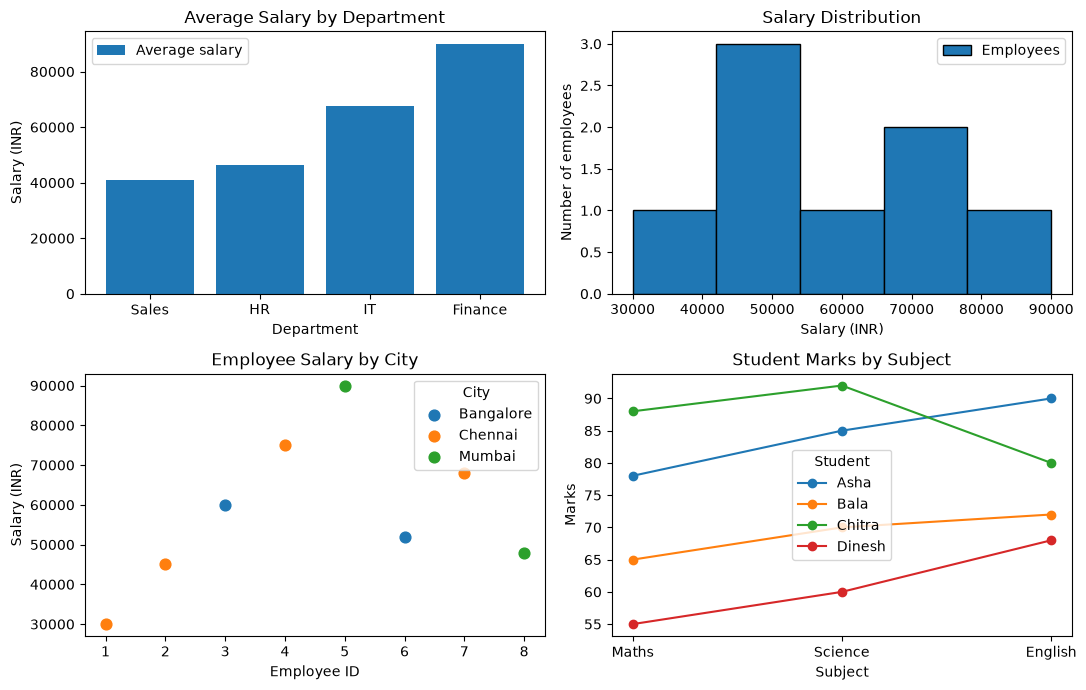

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

axes[0, 0].bar(summary.index, summary['avg_salary'], label='Average salary')
axes[0, 0].set(title='Average Salary by Department', xlabel='Department', ylabel='Salary (INR)')
axes[0, 0].legend()

axes[0, 1].hist(df['salary'], bins=5, edgecolor='black', label='Employees')
axes[0, 1].set(title='Salary Distribution', xlabel='Salary (INR)', ylabel='Number of employees')
axes[0, 1].legend()

for city, g in df.groupby('city'):
    axes[1, 0].scatter(g['id'], g['salary'], label=city, s=60)
axes[1, 0].set(title='Employee Salary by City', xlabel='Employee ID', ylabel='Salary (INR)')
axes[1, 0].legend(title='City')

for name, row in zip(['Asha', 'Bala', 'Chitra', 'Dinesh'], marks):
    axes[1, 1].plot(['Maths', 'Science', 'English'], row, marker='o', label=name)
axes[1, 1].set(title='Student Marks by Subject', xlabel='Subject', ylabel='Marks')
axes[1, 1].legend(title='Student')

fig.tight_layout()
plt.show()

## 7. Insights
- **Bar:** Finance has the highest average salary (90000) and Sales the lowest (41000).
- **Histogram:** The most common salary range is 42000-54000, with 3 of 8 employees.
- **Scatter:** Mumbai has the highest average salary by city (69000).
- **Line:** Chitra has the best average mark (86.67) and Dinesh the lowest (61.00).